# Notebook 03: Exploratory Data Analysis & Visualization

Analyze the processed data across all 12 Indian cities to understand:
1. GHI statistics and distributions by climate zone
2. Seasonal and diurnal patterns
3. Feature correlations
4. Cross-city comparisons
5. Data quality assessment

In [3]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sys.path.insert(0, os.path.abspath('.'))

from utils.city_config import CITY_METADATA, get_training_cities, get_test_cities, get_all_cities
from utils.plotting import setup_plot_style, CITY_COLORS, COLORS

setup_plot_style()
os.makedirs('results/figures', exist_ok=True)

# Load processed data
city_data = {}
for city in get_all_cities():
    pq = Path(f'data/processed/parquet/{city}_processed.parquet')
    if pq.exists():
        city_data[city] = pd.read_parquet(pq)
        print(f"  Loaded {city}: {len(city_data[city]):,} rows")
    else:
        print(f"  MISSING: {city}")

print(f"\nLoaded {len(city_data)} cities")

  Loaded jaipur: 92,016 rows
  Loaded delhi: 100,776 rows
  Loaded guwahati: 100,776 rows
  Loaded ahmedabad: 100,776 rows
  Loaded chennai: 100,776 rows
  Loaded thiruvananthapuram: 100,776 rows
  Loaded nagpur: 100,776 rows
  Loaded hyderabad: 100,776 rows
  Loaded bangalore: 100,776 rows
  Loaded kolkata: 100,776 rows
  Loaded lucknow: 100,776 rows
  Loaded jodhpur: 100,776 rows

Loaded 12 cities


## 1. GHI Statistics by City & Climate Zone

In [4]:
# Summary statistics for daylight GHI
stats_rows = []
for city, df in city_data.items():
    info = CITY_METADATA[city]
    ghi = df['ALLSKY_SFC_SW_DWN']
    daylight = ghi[ghi > 10]
    stats_rows.append({
        'City': city.title(),
        'Role': 'Train' if info['role'] == 'train' else 'Test',
        'Climate': info['climate_zone'],
        'Mean GHI': daylight.mean(),
        'Std GHI': daylight.std(),
        'Median GHI': daylight.median(),
        'Max GHI': daylight.max(),
        'P90 GHI': daylight.quantile(0.90),
        'Daylight Hours': len(daylight),
    })
stats_df = pd.DataFrame(stats_rows).sort_values('Mean GHI', ascending=False)
display(stats_df.style.format({'Mean GHI': '{:.1f}', 'Std GHI': '{:.1f}', 
                                'Median GHI': '{:.1f}', 'Max GHI': '{:.1f}', 
                                'P90 GHI': '{:.1f}'}))

,City,Role,Climate,Mean GHI,Std GHI,Median GHI,Max GHI,P90 GHI,Daylight Hours
11,Jodhpur,Test,BWh,463.2,288.4,475.7,1085.6,853.4,50103
8,Bangalore,Test,Aw,456.9,282.2,460.8,1086.8,847.3,49602
3,Ahmedabad,Train,BSh,456.7,287.0,458.7,1089.3,848.2,49785
5,Thiruvananthapuram,Train,Am,452.7,285.5,456.7,1041.7,844.0,49765
0,Jaipur,Train,BWh,443.3,283.2,446.6,1098.2,832.1,45652
7,Hyderabad,Test,BSh,436.4,278.0,435.9,1060.4,815.1,49936
4,Chennai,Train,Aw,433.3,277.3,427.8,1019.8,813.3,49997
6,Nagpur,Train,Aw,423.3,280.7,409.4,1091.1,814.3,49984
1,Delhi,Train,Cwa,403.0,267.8,387.3,1053.2,784.4,50022
10,Lucknow,Test,Cwa,400.4,268.4,384.4,1044.2,783.7,49781


## 2. Diurnal Profiles by Climate Zone

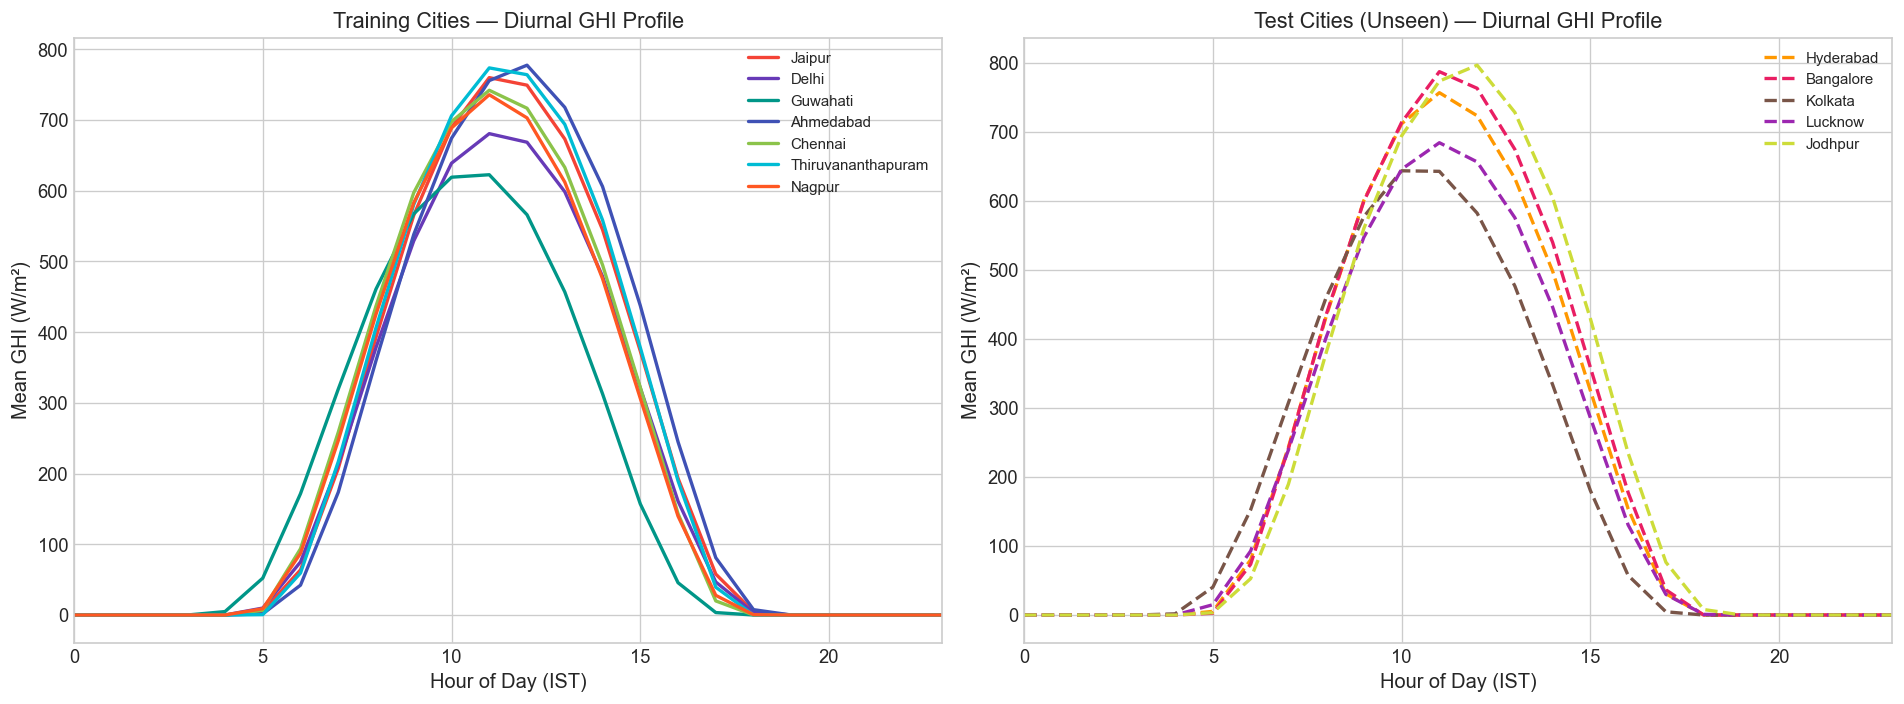

In [5]:
# Average diurnal profile per city
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Training cities
ax = axes[0]
for city in get_training_cities():
    if city not in city_data:
        continue
    df = city_data[city]
    hourly = df.groupby(df['timestamp'].dt.hour)['ALLSKY_SFC_SW_DWN'].mean()
    color = CITY_COLORS.get(city, '#333')
    ax.plot(hourly.index, hourly.values, label=city.title(), color=color, linewidth=2)
ax.set_xlabel('Hour of Day (IST)')
ax.set_ylabel('Mean GHI (W/m²)')
ax.set_title('Training Cities — Diurnal GHI Profile')
ax.legend(fontsize=9)
ax.set_xlim(0, 23)

# Test cities
ax = axes[1]
for city in get_test_cities():
    if city not in city_data:
        continue
    df = city_data[city]
    hourly = df.groupby(df['timestamp'].dt.hour)['ALLSKY_SFC_SW_DWN'].mean()
    color = CITY_COLORS.get(city, '#333')
    ax.plot(hourly.index, hourly.values, label=city.title(), color=color, linewidth=2, linestyle='--')
ax.set_xlabel('Hour of Day (IST)')
ax.set_ylabel('Mean GHI (W/m²)')
ax.set_title('Test Cities (Unseen) — Diurnal GHI Profile')
ax.legend(fontsize=9)
ax.set_xlim(0, 23)

plt.tight_layout()
plt.savefig('results/figures/03_diurnal_profiles.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Seasonal Patterns

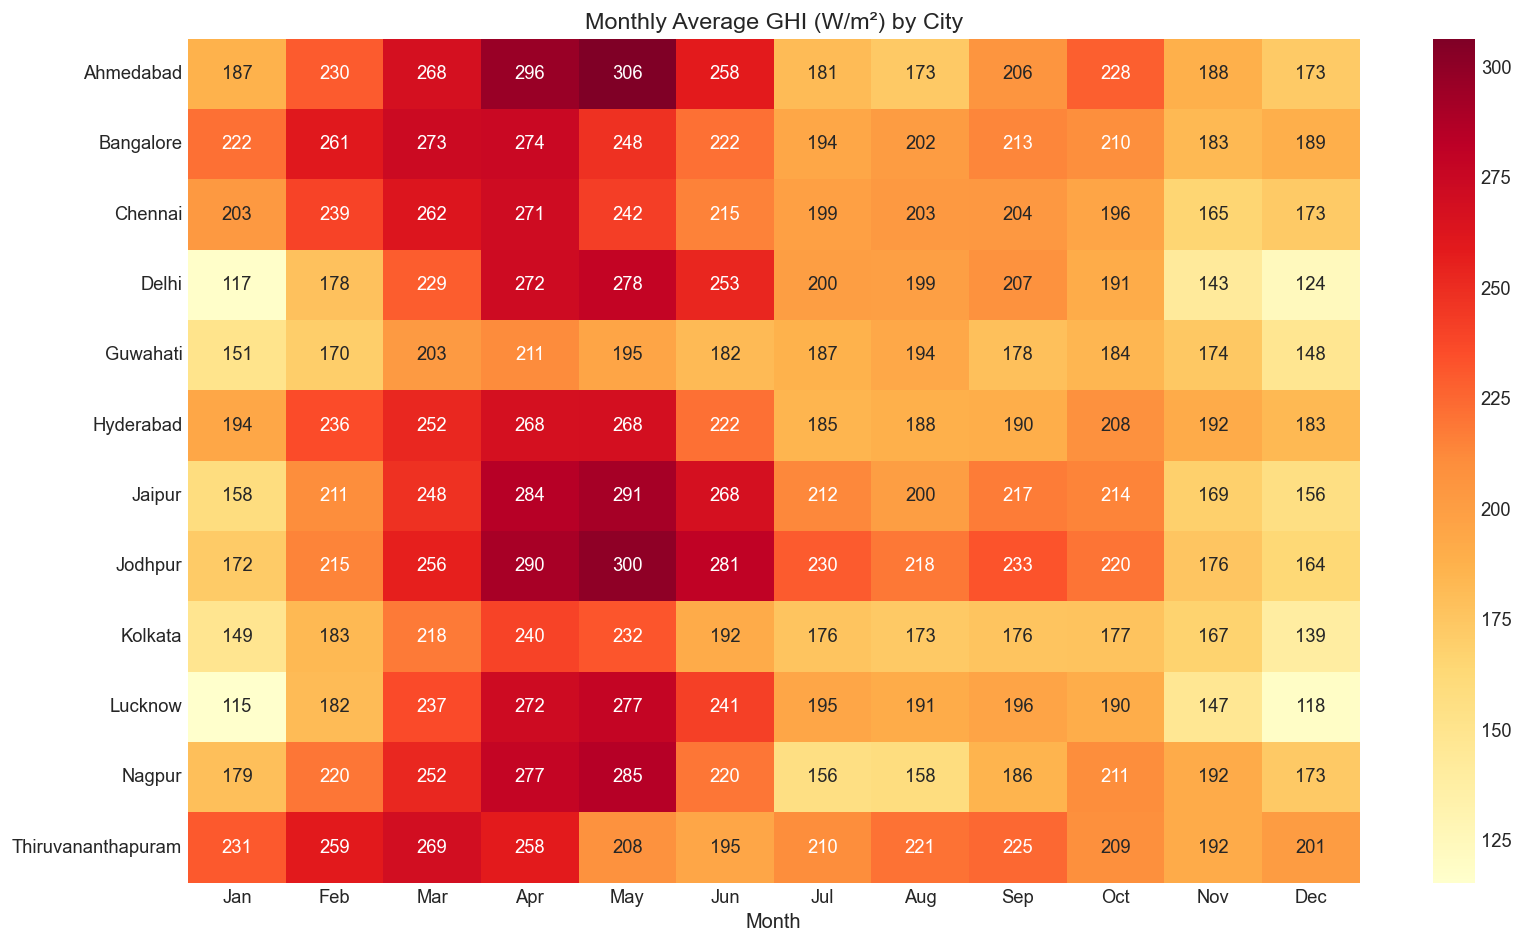

In [6]:
# Monthly average GHI heatmap
monthly_data = []
for city, df in city_data.items():
    monthly = df.groupby(df['timestamp'].dt.month)['ALLSKY_SFC_SW_DWN'].mean()
    for month, val in monthly.items():
        monthly_data.append({'City': city.title(), 'Month': month, 'GHI': val})

monthly_df = pd.DataFrame(monthly_data)
pivot = monthly_df.pivot(index='City', columns='Month', values='GHI')

fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlOrRd', ax=ax,
            xticklabels=['Jan','Feb','Mar','Apr','May','Jun',
                         'Jul','Aug','Sep','Oct','Nov','Dec'])
ax.set_title('Monthly Average GHI (W/m²) by City', fontsize=14)
ax.set_ylabel('')
plt.tight_layout()
plt.savefig('results/figures/03_monthly_ghi_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Feature Correlation Analysis

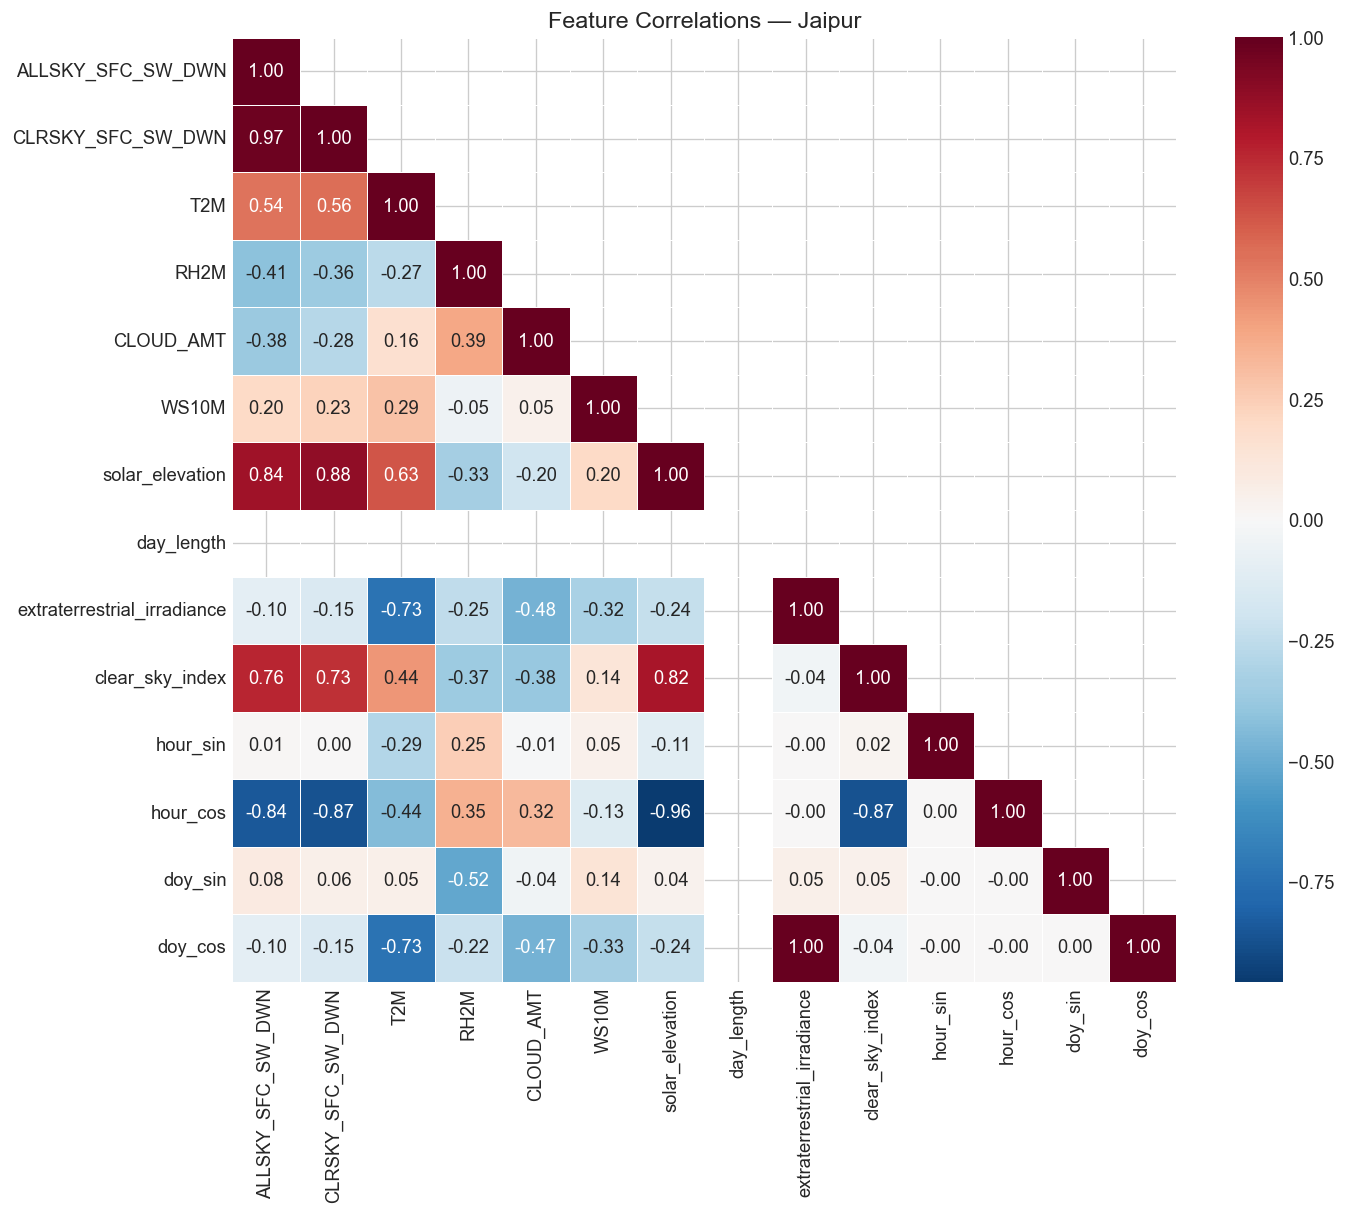


Top correlations with GHI (Jaipur):
  CLRSKY_SFC_SW_DWN                   +0.973
  hour_cos                            -0.844
  solar_elevation                     +0.842
  clear_sky_index                     +0.758
  T2M                                 +0.540
  RH2M                                -0.413
  CLOUD_AMT                           -0.375
  WS10M                               +0.203
  doy_cos                             -0.101
  extraterrestrial_irradiance         -0.097
  doy_sin                             +0.084
  hour_sin                            +0.011
  day_length                          +nan


In [7]:
# Correlation with GHI target for a representative city
rep_city = get_training_cities()[0]  # Jaipur
df_rep = city_data[rep_city]

# Select numeric columns for correlation
corr_cols = ['ALLSKY_SFC_SW_DWN', 'CLRSKY_SFC_SW_DWN', 'T2M', 'RH2M', 
             'CLOUD_AMT', 'WS10M', 'solar_elevation', 'day_length',
             'extraterrestrial_irradiance', 'clear_sky_index',
             'hour_sin', 'hour_cos', 'doy_sin', 'doy_cos']
corr_cols = [c for c in corr_cols if c in df_rep.columns]

corr_matrix = df_rep[corr_cols].corr()

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, ax=ax, square=True, linewidths=0.5)
ax.set_title(f'Feature Correlations — {rep_city.title()}', fontsize=14)
plt.tight_layout()
plt.savefig('results/figures/03_feature_correlations.png', dpi=150, bbox_inches='tight')
plt.show()

# Top correlations with GHI
ghi_corr = corr_matrix['ALLSKY_SFC_SW_DWN'].drop('ALLSKY_SFC_SW_DWN').sort_values(key=abs, ascending=False)
print(f"\nTop correlations with GHI ({rep_city.title()}):")
for feat, val in ghi_corr.items():
    print(f"  {feat:35s} {val:+.3f}")

## 5. Cross-City Climate Comparison

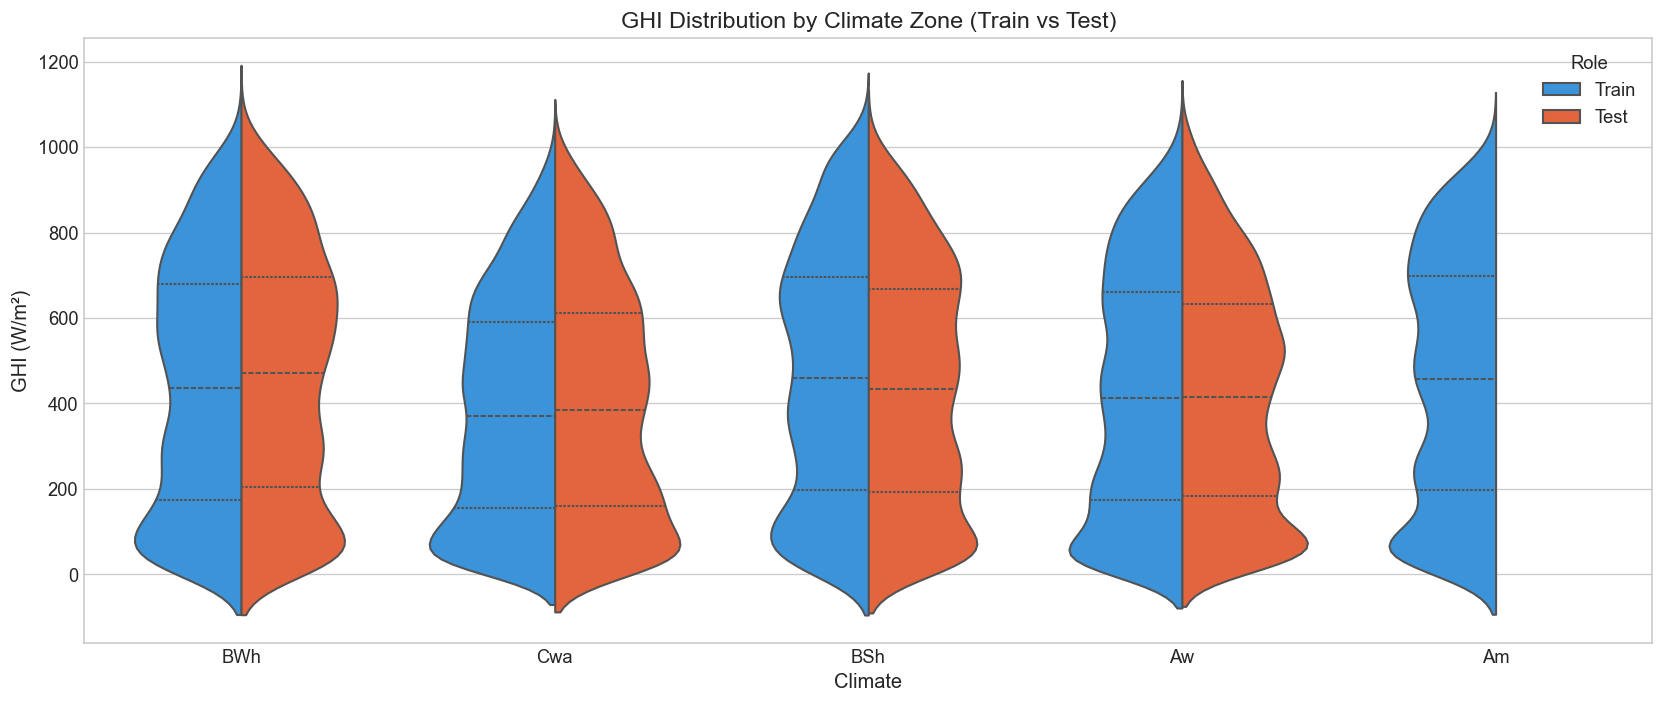

In [8]:
# Violin plot of daylight GHI by climate zone
violin_data = []
for city, df in city_data.items():
    info = CITY_METADATA[city]
    ghi = df['ALLSKY_SFC_SW_DWN'].values
    daylight = ghi[ghi > 10]
    # Sample for efficiency
    sample = np.random.choice(daylight, min(5000, len(daylight)), replace=False)
    for val in sample:
        violin_data.append({
            'GHI': val,
            'Climate': info['climate_zone'],
            'City': city.title(),
            'Role': 'Train' if info['role'] == 'train' else 'Test',
        })

vdf = pd.DataFrame(violin_data)

fig, ax = plt.subplots(figsize=(14, 6))
sns.violinplot(data=vdf, x='Climate', y='GHI', hue='Role', split=True, ax=ax,
               palette={'Train': '#2196F3', 'Test': '#FF5722'}, inner='quartile')
ax.set_title('GHI Distribution by Climate Zone (Train vs Test)', fontsize=14)
ax.set_ylabel('GHI (W/m²)')
plt.tight_layout()
plt.savefig('results/figures/03_climate_violin.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Temporal Coverage & Data Quality

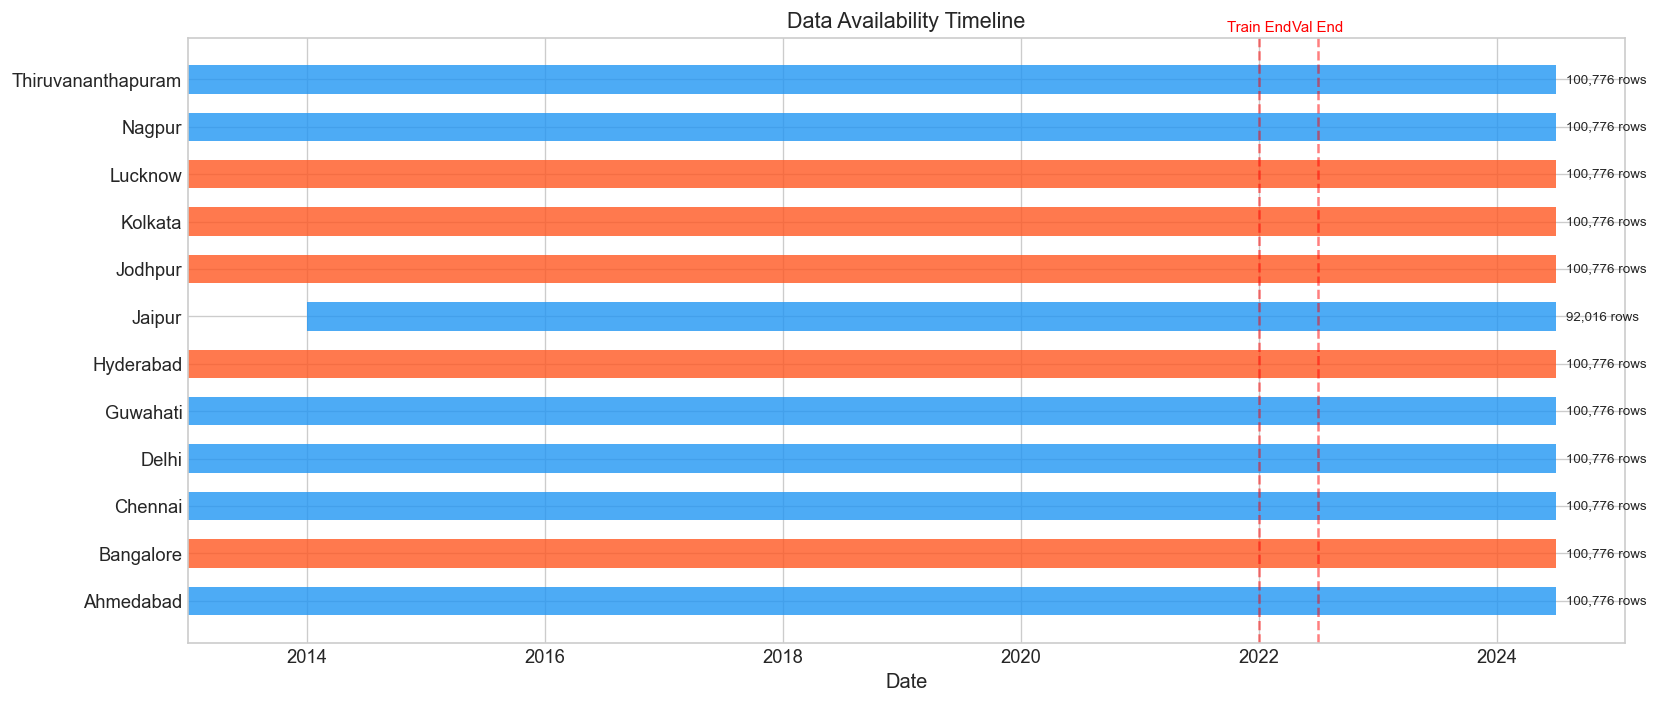

In [9]:
# Data availability timeline
fig, ax = plt.subplots(figsize=(14, 6))

cities = sorted(city_data.keys())
for i, city in enumerate(cities):
    df = city_data[city]
    start = df['timestamp'].min()
    end = df['timestamp'].max()
    info = CITY_METADATA[city]
    color = '#2196F3' if info['role'] == 'train' else '#FF5722'
    ax.barh(i, (end - start).days, left=start, height=0.6, color=color, alpha=0.8)
    ax.text(end + pd.Timedelta(days=30), i, f"{len(df):,} rows", va='center', fontsize=8)

ax.set_yticks(range(len(cities)))
ax.set_yticklabels([c.title() for c in cities])
ax.set_xlabel('Date')
ax.set_title('Data Availability Timeline')

# Add split markers
from utils.city_config import TRAIN_END, VAL_END
for date, label in [(TRAIN_END, 'Train End'), (VAL_END, 'Val End')]:
    ax.axvline(pd.Timestamp(date), color='red', linestyle='--', alpha=0.5)
    ax.text(pd.Timestamp(date), len(cities), label, ha='center', fontsize=9, color='red')

plt.tight_layout()
plt.savefig('results/figures/03_data_timeline.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Clear Sky Index Analysis

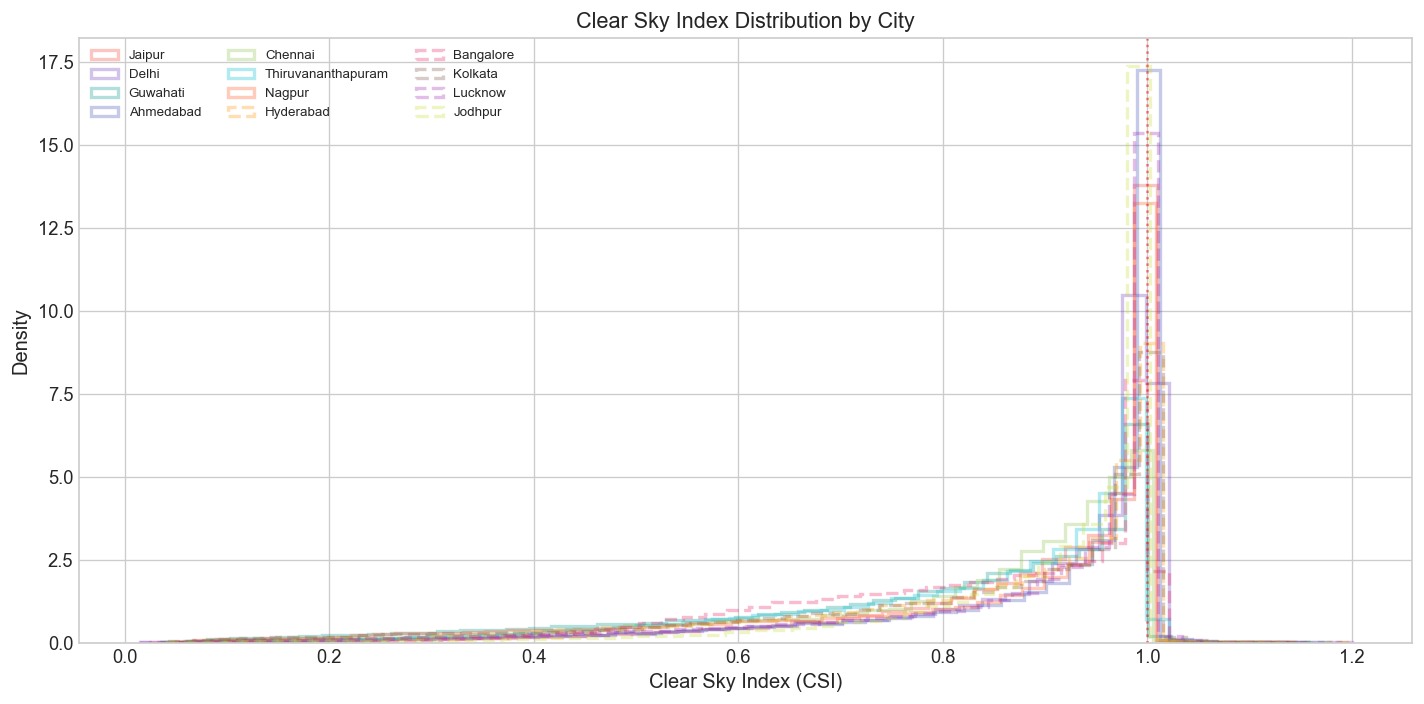

In [10]:
# Clear Sky Index (CSI) distribution — measures cloud impact
fig, ax = plt.subplots(figsize=(12, 6))

for city in get_all_cities():
    if city not in city_data:
        continue
    df = city_data[city]
    if 'clear_sky_index' in df.columns:
        csi = df['clear_sky_index'].dropna()
        csi = csi[(csi > 0) & (csi <= 1.2)]
        color = CITY_COLORS.get(city, '#333')
        info = CITY_METADATA[city]
        ls = '-' if info['role'] == 'train' else '--'
        ax.hist(csi, bins=50, alpha=0.3, color=color, label=city.title(), 
                density=True, histtype='step', linewidth=2, linestyle=ls)

ax.set_xlabel('Clear Sky Index (CSI)')
ax.set_ylabel('Density')
ax.set_title('Clear Sky Index Distribution by City')
ax.legend(fontsize=8, ncol=3)
ax.axvline(1.0, color='red', linestyle=':', alpha=0.5, label='Clear sky')
plt.tight_layout()
plt.savefig('results/figures/03_csi_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## Summary

Key findings:
- Desert cities (Jaipur, Jodhpur) have highest mean GHI and clearest skies
- Monsoon creates a distinct seasonal dip (Jun-Sep) across all cities
- Coastal cities show more cloud variability (lower CSI)
- Training cities span the full range of Indian solar climates
- Test cities fall within the distribution of training cities (good generalization setup)

**Next:** Notebook 04 — Baseline Models (Persistence, SARIMA, LSTM, Transformer)